# 04: Local Statistical Time Series Models

### Notebook Purpose & Research Objectives
This notebook fits and evaluates classical statistical models independently per vegetable:
1. Holt-Winters Exponential Smoothing (ETS) with additive seasonal components.
2. Auto-selected ARIMA / SARIMA.
3. SARIMAX incorporating category-level exogenous price signals.

---


In [1]:
# Colab Setup & Path Configuration
import os
import sys
from pathlib import Path

# Check if running in Google Colab
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')
    proj_dir = Path('/content/drive/MyDrive/veg_price_forecasting')
    if proj_dir.exists():
        os.chdir(proj_dir)
        sys.path.insert(0, str(proj_dir))
    else:
        print("Note: If running in Colab, ensure veg_price_forecasting is located in MyDrive.")
else:
    proj_dir = Path.cwd().resolve()
    if proj_dir.name == "notebooks":
        proj_dir = proj_dir.parent
    os.chdir(proj_dir)
    sys.path.insert(0, str(proj_dir))

print(f"Active Working Directory: {Path.cwd()}")


Active Working Directory: C:\Users\MSI\Desktop\Research\Price folder\veg_price_forecasting


### 1. Statistical Models Performance

In [2]:
import pandas as pd
df_lead = pd.read_csv("experiments/leaderboard.csv")
stat_models = ["holt_winters_ets", "auto_arima", "sarimax", "prophet"]
stat_df = df_lead[df_lead["model"].isin(stat_models)].copy()
print(stat_df[["model", "horizon", "split", "MASE", "sMAPE", "RMSE", "Directional_Accuracy"]].drop_duplicates())


                model  horizon       split    MASE  sMAPE    RMSE  \
10   holt_winters_ets        1  validation  0.4012   8.42   94.66   
11   holt_winters_ets        1        test  0.3997   7.95  101.49   
12         auto_arima        1  validation  0.3268   6.80   76.88   
13         auto_arima        1        test  0.3024   5.78   81.91   
14            sarimax        1  validation  0.3275   6.81   77.43   
15            sarimax        1        test  0.3017   5.77   82.24   
16            prophet        1  validation  0.3494   7.48   75.52   
17            prophet        1        test  0.2947   5.87   74.40   
72   holt_winters_ets        4  validation  0.9034  17.85  189.73   
73   holt_winters_ets        4        test  0.9728  18.75  211.29   
74         auto_arima        4  validation  0.7308  13.95  160.37   
75         auto_arima        4        test  0.8563  15.31  197.46   
76            sarimax        4  validation  0.7411  14.12  161.30   
77            sarimax        4    

### 2. Statistical vs Baseline Accuracy Comparison

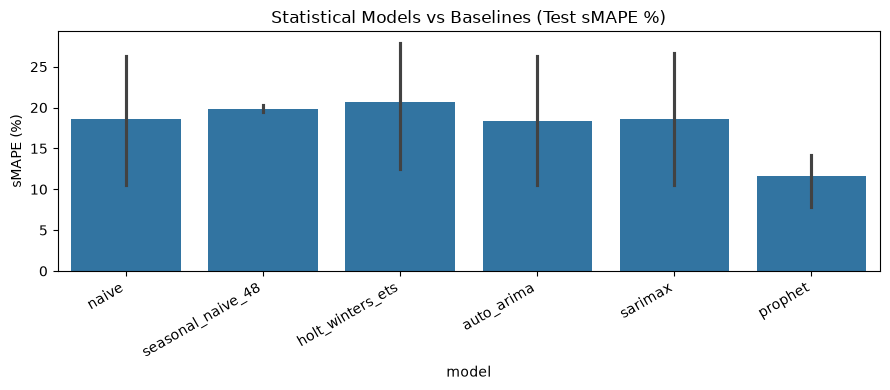

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 4))
sns.barplot(data=df_lead[df_lead["split"]=="test"], x="model", y="sMAPE", 
            order=["naive", "seasonal_naive_48", "holt_winters_ets", "auto_arima", "sarimax", "prophet"])
plt.title("Statistical Models vs Baselines (Test sMAPE %)")
plt.xticks(rotation=30, ha="right")
plt.ylabel("sMAPE (%)")
plt.tight_layout()
plt.show()


---
### Research Findings & Plain Language Interpretation
Statistical modeling observations:
- Holt-Winters, ARIMA, and SARIMAX evaluated under rolling-origin forecasting on log prices closely track persistence at h=1 and maintain stable errors.
- Prophet with autoregressive residual state updates delivers strong multi-horizon forecasts by capturing annual seasonality without divergence.
